### Klasifikacija rezencija mobilnih aplikacija pomocu biblioteka spaCy i sklearn (Vector Space Model i Logistic Resgression)

Skup podataka i zadatak su isti kao prosle nedelje, samo sto sad koristimo **Vector Space Model (VSP)** pristup za predstavljanje teksta i algoritam logicke regresije (**Logistic Regression – LR**) za klasifikaciju rezencija korisnika aplikacija.

In [1]:
# UCITAVANJE POTREBNIH BIBLIOTEKA

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.base import TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from IPython.display import display

import re
import spacy

import json
from pathlib import Path

In [2]:
RAND_STATE = 1

#### UCITAVANJE I PREGLED PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'mobile_apps_reviews.csv')

In [4]:
data.head(10)

,id,app,version,rating,date,device,user,review,category
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER
5,6,com.androtiyas.dragonvirtual,1.11,5,1391710690867,?,Aribha Zahoor,hope this is a good game!!!! ?,OTHER
6,7,com.androtiyas.dragonvirtual,?,1,1396716326980,LG Optimus One,isaiah lawrence,sucks can't even play offline and everyone tak...,FEATURE
7,8,com.androtiyas.dragonvirtual,1.12,5,1397085800819,Samsung Galaxy Y,Charlotte Baynes,good that is so good,OTHER
8,9,com.androtiyas.dragonvirtual,1.1,5,1389305213694,HTC Wildfire S,A Google User,? realy good and fun,OTHER
9,10,com.androtiyas.dragonvirtual,1.11,5,1391957108087,?,Jennifer Bieber,999 this is the best,OTHER


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        3000 non-null   int64 
 1   app       3000 non-null   object
 2   version   3000 non-null   object
 3   rating    3000 non-null   int64 
 4   date      3000 non-null   int64 
 5   device    3000 non-null   object
 6   user      2991 non-null   object
 7   review    3000 non-null   object
 8   category  3000 non-null   object
dtypes: int64(3), object(6)
memory usage: 211.1+ KB


#### KREIRANJE IZLAZNE PROMENLJIVE

In [6]:
# pravimo novu kolonu cls sa 3 moguce vrednosti: OTHER, FUNCTIONAL (BUG, FEATURE) i NON-FUNCTIONAL (PERFORMANCE, USABILITY, ENERGY, SECURITY)

def category_to_cls(cat):
    if cat == 'OTHER': return cat
    return 'FUNCTIONAL' if cat in ['BUG', 'FEATURE'] else 'NON-FUNCTIONAL'


data['cls'] = data.category.apply(category_to_cls)

data.cls.value_counts(normalize=True)

cls
OTHER             0.501667
FUNCTIONAL        0.365667
NON-FUNCTIONAL    0.132667
Name: proportion, dtype: float64

#### PREDIKTORI

In [7]:
# kao i prethodne nedelje zadrzavamo tri prediktora (rating, review_len, review) i izlaznu varijablu (cls)

data['review_len'] = data.review.apply(len)

data_sub = data[['rating', 'review_len', 'review', 'cls']]

data_sub.head()

,rating,review_len,review,cls
0,5,40,cute!!!! the game is just to cute!!!! :3,OTHER
1,4,41,? well its ok but not bad nor is it great,OTHER
2,1,60,? have no idea how to feed dragon and boooorrr...,OTHER
3,2,295,when i play games it reboots about every third...,FUNCTIONAL
4,5,43,love my dragon have fun! yahoooey! godbless,OTHER


### CISCENJE TEKSTA (opciono)

**! NECE SE TRAZITI NA KOLOKVIJUMU, ALI ZA PROJEKAT CE SVAKAKO BITI NEOPHODNO !**

Ako su tekstualni podaci prikupljeni sa veb-sajtova, foruma, drustvenih mreza i slicnih izvora, cesto ih je potrebno **ocistiti pre nego sto se proslede biblioteci spaCy na pretprocesiranje**.

Ciscenje obicno obuhvata uklanjanje:
- HTML oznaka (*HTML markup*)
- linkova
- hastagova (*hashtags*)
- i slicnih elemenata koji mogu da ometaju dalju obradu teksta.

[PODSETNIK ZA REGEX](https://www.dataquest.io/cheat-sheet/regular-expressions-cheat-sheet/)

In [8]:
def clean_text(text):
    text = re.sub(r"(?:^|\s)#(\w+)", " \\1", text)  # uklanja #
    text = re.sub(r"(?:^|\s)@(\w+)", "", text)  # uklanja reference na druge korisnike
    text = re.sub("<[^>]+>", "", text)  # uklanja HTML mark-up
    text = text.strip()

    return text

In [9]:
# primer
print(clean_text("love my #dragon have #fun"))
print(clean_text("this is the best - recommend to @all"))
print(clean_text("<b>don't like it at all</b>"))

love my dragon have fun
this is the best - recommend to
don't like it at all


Da bismo mogli da ukljucimo komponentu za ciscenje teksta u proces izgradnje modela, napravicemo prilagodjeni transformator nasledjivanjem osnovne klase scikit-learn biblioteke za sve transformatore (`TransformerMixin`).

Ovo je neophodno kako bismo mogli da ga ukljucimo u `Pipeline` biblioteke scikit-learn, jer se u njega mogu ukljuciti samo transformatori i modeli (*estimatori*).

Ovo će biti prvi korak u pretprocesiranju teksta i celokupnom procesu obrade, nakon čega sledi korak **vektorizacije**.

In [10]:
class TextCleaner(TransformerMixin):

    def transform(self, X):
        # X je ceo dataframe iz training seta
        X['review'] = [clean_text(txt) for txt in X['review']]
        # sofvtverski bi bilo najbolje da je metoda clean_text u okviru ove klase
        return X

    def fit(self, X, y=None):
        return self

#### KORISCENJE SPACY ZA PRETPROCESIRANJE TEKSTA

In [11]:
# isti princip kao prosle nedelje

nlp_pipe = spacy.load('en_core_web_sm')

In [12]:
# ista funkcija

def spacy_preprocessing(doc):
    # kreiranje tokena sa lingvistickim osobinama
    tokens = nlp_pipe(doc)
    # uklanjanje interpunkcija, praznina, brojeva i url
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space) and
                  (not token.like_num) and (not token.like_url))]
    # uklanjanje stop words (ostavljamo not)
    tokens = [token for token in tokens
              if ((not token.is_stop) or (token.lemma_.lower() == 'not'))]

    # pretvaranje tokena u lemme
    words = [token.lemma_.lower() for token in tokens]

    # vracanje pretprocesuiranih reci
    return words

### TEKST TRANSFORMACIJA KORISCENJEM TF-IDF

**TF-IDF (Term Frequency – Inverse Document Frequency)** je nacin predstavljanja teksta pomocu brojeva. Koristi se za izgradnju **Vector Space Model-a (VSM)**, odnosno moela vektorskog prostora u kojem se svaki dokument predstavlja kao vektor brojeva, pri cemu svaki broj predstavlja **TF-IDF tezinu odredjene reci iz recnika u tom dokumentu**.

TF-IDF se sastoji iz dva dela:

- **TF (Term Frequency)** – predstavlja ucestalost pojavljivanja odredjene reci u konkretnom dokumentu. Sto se rec cesce pojavljuje u dokumentu, njena TF vrednost je veca.
- **IDF (Inverse Document Frequency)** – predstavlja koliko je rec retka u celom skupu dokumenata. Reci koje se pojavljuju u velikom broju dokumenata dobijaju manju IDF vrednost, dok reci koje se pojavljuju u manjem broju dokumenata dobijaju vecu vrednost.

**TF-IDF tezina** dobija se kombinovanjem ove dve vrednosti. Na taj nacin, vecu tezinu mogu dobiti reci koje su znacajne za konkretan dokument, a ne pojavljuju se u velikom broju drugih dokumenata. Reci koje se pojavljuju gotovo svuda obicno imaju manju sposobnost razlikovanja dokumenata.

Rezultat je **matrica** (document-term) u kojoj:

- **redovi** predstavljaju dokumente,
- **kolone** predstavljaju reci iz recnika,
- **celije** predstavljaju TF-IDF tezinu odredjene reci u odredjenom dokumentu (0-1).

Matrica je najcesce **retka (*sparse*)**, jer se vecina reci iz celog recnika ne pojavljuje u svakom dokumentu, pa se u vecini celija nalaze nule.

**TfidfVectorizer** iz biblioteke `sklearn` koristi se za pretvaranje tekstualnih dokumenata u TF-IDF matricu. On formira recnik na osnovu skupa dokumenata, odredjuje ucestalost reci i izracunava njihove TF-IDF tezine.

`TfidfVectorizer` moze da izvrsi i odredjene osnovne korake obrade teksta, kao sto su pretvaranje slova u mala slova i tokenizacija prema podrazumevanim pravilima. Takodje, mozemo mu proslediti sopstvenu funkciju za tokenizaciju pomocu argumenta `tokenizer`.

Ako se pre vektorizacije izvrsava dodatna obrada teksta – na primer uklanjanje brojeva, URL-ova, znakova, stop reci ili lematizacija – ti koraci se izvrsavaju pre formiranja TF-IDF reprezentacije.

Proces tada mozemo posmatrati ovako: **originalni tekst -> preprocessing/tokenizacija -> formiranje recnika -> izracunavanje TF-IDF tezina -> VSM (matrica vektora dokumenata)**.

**Glavna razlika u odnosu na BoW:** BoW belezi koliko puta se rec pojavljuje u dokumentu, dok TF-IDF dodeljuje tezinu koja uzima u obzir i ucestalost reci u dokumentu i njenu zastupljenost u celom skupu dokumenata. U oba pristupa redosled reci se gubi.

In [13]:
def create_tfidf_vectoriser(ngrams=(1, 2), min_doc_freq=0.01):
    vectoriser = TfidfVectorizer(
        tokenizer=spacy_preprocessing,  # umesto ugradjenog deljenja teksta, koristimo svoju funkciju
        token_pattern=None,  # kazemo da ne koristi regex
        ngram_range=ngrams,
        min_df=min_doc_freq,  # rec ulazi u recnik samo ako se pojavljuje u najmanje _% dokumenta
        norm='l2',
        smooth_idf=True
    )

    return vectoriser

# norm=l2 - izracuna se kvadratni koren zbira kvadrata svih vrednosti u vektoru, vektor se zatim skalira tako da njegova norma bude 1
# smooth_idf=True - izbegavanje problema sa deljenjem nulom i logaritmom nule prilikom racunavanja IDF vrednosti

**za bolje razumevanje hiperparametara `norm` i `smooth_idf`**: [Section 7.2.3.5 of the sklearn's User Guide](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting)

In [14]:
vectorized_example = create_tfidf_vectoriser()
vectorized_reviews = vectorized_example.fit_transform(data_sub.review)
df = pd.DataFrame(data=vectorized_reviews.toarray(), columns=vectorized_example.get_feature_names_out())

display(df.shape)
display(df.iloc[:10, :10])

(3000, 183)

,ability,able,accurate,ad,add,add feature,allow,amazing,android,app
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### KREIRANJE I TRENIRANJE PIPELINE-A ZA KLASIFIKACIJU TEKSTA

* PODELA NA TRAIN I TEST
* KREIRANJE COLUMN TRANSFORMERA
* KREIRANJE KLASIFIKATORA
* PIPELINE

In [15]:
# PODELA NA TRAIN I TEST

X = data_sub[['review', 'review_len', 'rating']]
y = data_sub.cls.values

y_encodings, y_levels = pd.factorize(y)
# prosle nedelje faktorizacija nije bila obavezna jer stablo moze da radi sa tekstom, ovde su OBAVEZNE NUMERICKE VREDNOSTI

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encodings,
    test_size=0.2,
    random_state=RAND_STATE,
    stratify=y_encodings
)

In [16]:
# KREIRANJE COLUMN TRANSFORMERA

tf_idf_vectorizer = create_tfidf_vectoriser()  # za transformaciju kolone review u document-term matricu

# logisticka regresija postavlja neka ogranicenja - varijable moraju da budu u slicnim opsezima (zato koristimo scaler)
scaler = RobustScaler()

column_transformer = ColumnTransformer(
    [('tf_idf', tf_idf_vectorizer, 'review'),
     ('scaler', scaler, ['review_len', 'rating'])]
)

In [17]:
# KREIRANJE KLASIFIKATORA

classifier = LogisticRegression(random_state=RAND_STATE, max_iter=2000)

In [18]:
# PIPELINE

pipe = Pipeline(
    [('cleaner', TextCleaner()),
     ('transformator', column_transformer),
     ('classifier', classifier)]
)

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('cleaner', ...), ('transformator', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tf_idf', ...), ('scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different t

#### EVALUACIJA MODELA

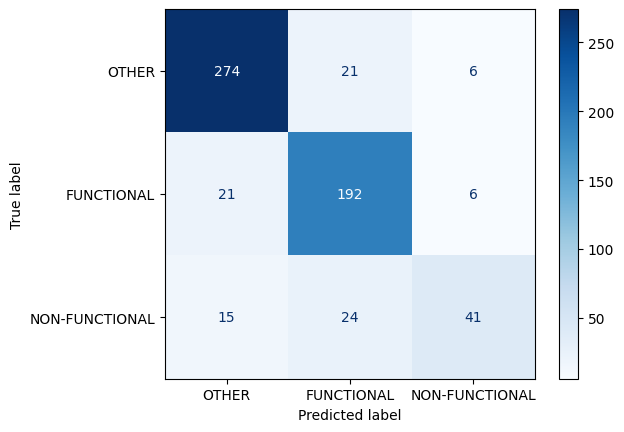

In [19]:
disp = metrics.ConfusionMatrixDisplay.from_estimator(
    pipe,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Blues'
)

In [20]:
predictions_1 = pipe.predict(X_test)

report_1 = metrics.classification_report(y_true=y_test, y_pred=predictions_1)
print(report_1)

              precision    recall  f1-score   support

           0       0.88      0.91      0.90       301
           1       0.81      0.88      0.84       219
           2       0.77      0.51      0.62        80

    accuracy                           0.84       600
   macro avg       0.82      0.77      0.79       600
weighted avg       0.84      0.84      0.84       600



In [21]:
display(f"Accuracy: {metrics.accuracy_score(y_test, predictions_1):0.4f}")
display(f"Balanced accuracy: {metrics.balanced_accuracy_score(y_test, predictions_1, adjusted=True):0.4f}")

'Accuracy: 0.8450'

'Balanced accuracy: 0.6498'

### POKUSAJ POBOLJSANJA KLASIFIKATORA PODESAVANJEM **HIPERPARAMETARA**

Sada cemo pokusati da poboljsamo performanse klasifikatora promenom nacina transformacije teksta i nacina na koji je podesen algoritam logisticke regresije.

Hiperparametri koji se cesto podesavaju kod TF-IDF vektorizatora ukljucuju:

- `min_df` – minimalna ucestalost ngrama u dokumentima.
- `ngram_range` – opseg n-grama koji ce se koristiti kao osobine (*features*).
- `max_features` – maksimalan broj n-grama koji se zadrzava, rangiranih prema njihovim TF-IDF vrednostima.

---------------------
Kada je u pitanju logisticka regresija u biblioteci `sklearn`, postoji nekoliko vaznih hiperparametara: `C`, `penalty` i `solver`.

Od njih se najcesce podesava `C` (*Inverse Regularization Strength* – inverzna jacina regularizacije), koji kontrolise ravnotezu izmedju prilagodjavanja trening podacima i izbegavanja preprilagodjavanja (*overfitting*).

- **Male vrednosti parametra `C`** dovode do jace regularizacije. One smanjuju koeficijente i stvaraju jednostavniji model, sa vecom pristrasnoscu (*bias*) i manjom varijansom (*variance*).
- **Vece vrednosti parametra `C`** podrazumevaju slabiju regularizaciju. To omogucava vece koeficijente i blize prilagodjavanje trening podacima, uz manju pristrasnost i veću varijansu.

Neke najcesce vrednosi za `C`: `0.01, 0.1, 1, 10 i 100`.

---------------------
**`penalty`** - vrsta regularizacije

Odredjuje nacin na koji se koeficijenti modela ogranicavaju kako bi se smanjila mogucnost preprilagodjavanja.

- **L1 regularizacija** – moze da postavi neke koeficijente na nulu, cime efektivno izbacuje odredjene osobine iz modela.
- **L2 regularizacija** – smanjuje velicine koeficijenata, ali ih obicno ne postavlja tacno na nulu.

Regularizacija pomaze da model ne pridaje preveliki znacaj pojedinacnim osobinama koje se pojavljuju u trening podacima.

---------------------
**`solver`** – algoritam optimizacije

Odredjuje algoritam koji se koristi za pronalazenje optimalnih koeficijenata logisticke regresije.

Primeri solvera su `lbfgs`, `liblinear` i `saga`.

Solveri se razlikuju po nacinu optimizacije, brzini i podrsci za odredjene vrste regularizacije. Nisu sve kombinacije parametara solver i penalty dozvoljene.

---------------------


Pokusacemo da odredimo optimalne vrednosti navedenih hiperparametara pomocu **unakrsne validacije (*Cross-Validation*)**, koristeci klasu [`RandomizedSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html).

**`Razlika izmedju GridSearchCV i RandomizedSearchCV`**:

- GridSearchCV ispituje sve zadate kombinacije hiperparametara.
- RandomizedSearchCV ispituje ogranicen broj nasumicno odabranih kombinacija.
- Kada postoji mnogo hiperparametara i mogucih kombinacija, `RandomizedSearchCV moze biti efikasniji` jer ne mora da ispita svaku kombinaciju.

---------------------

**Podsetnik:** nazivima hiperparametara mora da prethodi naziv odgovarajuce komponente (*transformera* ili *estimatora*) u *pipeline*. U ovom slucaju, nazivi relevantnih komponenti pipeline-a su `transformator` i `classifier`.

Medjutim, posto `transformator` nije jedan transformer, vec moze da sadrzi vise transformera — po jedan za svaku kolonu — potrebno je navesti naziv konkretnog transformera koji zelimo da podesimo. U ovom slucaju to je `tf_idf`.

Zato nazivu hiperparametra za transformaciju teksta moramo da dodamo prefiks `transformator__tf_idf__`.


In [22]:
# ! POTREBNO VREME - oko 20 minuta!

param_distributions = {
    'transformator__tf_idf__min_df': [0.005, 0.01, 0.025, 0.05],
    'classifier__C': np.logspace(-3, 3, 7)  #[0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
}

# np.logspace(start,stop,num):
# start -> eksponent od kojeg se pocinje tj. 10^start
# stop -> eksponent na kojem se zavrsava tj. 10^stop
# num -> broj vrednosti koje zelimo da dobijemo, ukljucujuci pocetnu i krajnju, vrednosti su ravnomerno rasporedjene na logaritamskoj skali, pa se svaka sledeca vrednost dobija mnozenjem prethodne sa 10^((stop-start)/(num-1))

random_seacrh = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=10,  # nasumicno probaj tacno 10 razlicitih kombinacija hiperparametara
    scoring='f1_macro',
    random_state=RAND_STATE,
    verbose=2
)

# f1 - harmonijska sredina precision i recall-a
# macro - daje svakoj klasi jednaku vaznost

# verbose=0 - ne ispisuje dodatne informacije tokom izvrsavanja
# verbose=1 - ispisuje osnovne informacije o napretku
# verbose=2 - ispisuje detaljnije informacije o svakom koraku

random_seacrh.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END classifier__C=1000.0, transformator__tf_idf__min_df=0.005; total time=  19.7s
[CV] END classifier__C=1000.0, transformator__tf_idf__min_df=0.005; total time=  19.2s
[CV] END classifier__C=1000.0, transformator__tf_idf__min_df=0.005; total time=  17.2s
[CV] END classifier__C=1000.0, transformator__tf_idf__min_df=0.005; total time=  17.1s
[CV] END classifier__C=1000.0, transformator__tf_idf__min_df=0.005; total time=  17.2s
[CV] END classifier__C=10.0, transformator__tf_idf__min_df=0.01; total time=  17.3s
[CV] END classifier__C=10.0, transformator__tf_idf__min_df=0.01; total time=  17.1s
[CV] END classifier__C=10.0, transformator__tf_idf__min_df=0.01; total time=  17.3s
[CV] END classifier__C=10.0, transformator__tf_idf__min_df=0.01; total time=  17.9s
[CV] END classifier__C=10.0, transformator__tf_idf__min_df=0.01; total time=  32.5s
[CV] END classifier__C=10.0, transformator__tf_idf__min_df=0.05; total time=  32.5s


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': array([1.e-03...e+02, 1.e+03]), 'transformator__tf_idf__min_df': [0.005, 0.01, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 `

In [23]:
print('Najbolji hipermarametri:')
for param, value in random_seacrh.best_params_.items():
    print(f"{param}: {value}")

print(f"\nNajbolji score (Macro F1): {random_seacrh.best_score_:.4f}")

Najbolji hipermarametri:
transformator__tf_idf__min_df: 0.01
classifier__C: 10.0

Najbolji score (Macro F1): 0.8296


In [24]:
# PONOVNO POKRETANJE PIPELINE SA OPTIMALNIM VREDNOSTIMA HIPERPARAMETARA

best_min_df = random_seacrh.best_params_['transformator__tf_idf__min_df']
best_C = random_seacrh.best_params_['classifier__C']

pipe.set_params(transformator__tf_idf__min_df=best_min_df,
                classifier__C=best_C)

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('cleaner', ...), ('transformator', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tf_idf', ...), ('scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different t

In [25]:
predictions_2 = pipe.predict(X_test)

report_2 = metrics.classification_report(y_true=y_test, y_pred=predictions_2)
print(report_2)

              precision    recall  f1-score   support

           0       0.87      0.89      0.88       301
           1       0.81      0.84      0.83       219
           2       0.70      0.56      0.62        80

    accuracy                           0.83       600
   macro avg       0.79      0.77      0.78       600
weighted avg       0.83      0.83      0.83       600



In [26]:
display(f"Accuracy: {metrics.accuracy_score(y_test, predictions_2):0.4f}")
display(f"Balanced accuracy: {metrics.balanced_accuracy_score(y_test, predictions_2, adjusted=True):0.4f}")

'Accuracy: 0.8300'

'Balanced accuracy: 0.6482'

#### POREDJENJE KREIRANIH MODELA

Sada cemo uporediti modele koje smo do sada napravili. Takodje cemo ukljuciti i `dummy klasifikator` kako bismo videli koliko su nasi modeli bolji u odnosu na najosnovniji klasifikator, koji generise predikcije tako sto prati raspodelu klasa u skupu za treniranje.

In [27]:
dummy_classifier = DummyClassifier(strategy='stratified')
# stratified - prati raspodelu klasa u skupu za treniranje

dummy_classifier.fit(X_train, y_train)

dummy_pred = dummy_classifier.predict(X_test)

report_dummy = metrics.classification_report(y_true=y_test, y_pred=dummy_pred)
print(report_dummy)

              precision    recall  f1-score   support

           0       0.51      0.48      0.49       301
           1       0.36      0.42      0.39       219
           2       0.11      0.09      0.10        80

    accuracy                           0.40       600
   macro avg       0.32      0.33      0.32       600
weighted avg       0.40      0.40      0.40       600



In [28]:
# sledeca f-ja izracunava metrike za procenu kvaliteta klasifikatora i vraca ih u obliku recnika radi poredjenja modela

def get_model_metrics(y_true: np.ndarray, y_pred: np.ndarray, model_name: str):
    # racunanje metrika
    report = metrics.classification_report(y_true, y_pred, output_dict=True)

    # balanced accuracy
    b_acc = metrics.balanced_accuracy_score(y_true, y_pred)

    # izdvajanje prosecnih rezultata
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc,
    }
    return results

In [29]:
def load_model_metrics_from_json(fpath: str, model_name: str):
    try:
        with open(fpath, 'r') as fobj:
            scored_dict = json.load(fobj)
    except OSError as err:
        print(f"Greska prilikom pokusaja citanja evaluacionih metrika za {model_name} iz {fpath}")
        return None

    # izdvajanje prosecnih rezultata
    macro_avg = scored_dict['macro avg']
    weighted_avg = scored_dict['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': None,
    }
    return results

In [30]:
model_predictions = {
    'TF-IDF-LR': predictions_1,
    'TF-IDF-LR-FT': predictions_2,
    'DUMMY': dummy_pred
}

all_results = list()

for model_name, model_pred in model_predictions.items():
    model_res = get_model_metrics(y_test, model_pred, model_name)
    all_results.append(model_res)

# MODEL OD PROSLE NEDELJE!!!
bow_results = load_model_metrics_from_json(Path.cwd() / 'results' / 'Bow_best_model_scores.json', 'BOW_DT_FT')
if bow_results:
    all_results.append(bow_results)

all_results_df = pd.DataFrame(all_results)
all_results_df.set_index("Model", inplace=True)
all_results_df = all_results_df.apply(lambda x: round(x, 4))

print('Poredjenje performansi modela:\n')
print(all_results_df)

Poredjenje performansi modela:

              Macro Precision  Macro Recall  Macro F1-Score  \
Model                                                         
TF-IDF-LR              0.8225        0.7665          0.7852   
TF-IDF-LR-FT           0.7947        0.7655          0.7774   
DUMMY                  0.3248        0.3260          0.3243   
BOW_DT_FT              0.8375        0.7425          0.7686   

              Weighted Precision  Weighted Recall  Weighted F1-Score  \
Model                                                                  
TF-IDF-LR                 0.8422           0.8450             0.8395   
TF-IDF-LR-FT              0.8263           0.8300             0.8270   
DUMMY                     0.4003           0.4017             0.3999   
BOW_DT_FT                 0.8381           0.8383             0.8288   

              Balanced Accuracy  
Model                            
TF-IDF-LR                0.7665  
TF-IDF-LR-FT             0.7655  
DUMMY               